# 05 Ablation Feature Groups

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

df = pd.read_csv('../dataset/pd_speech_features.csv', header=1)
X = df.drop(['id', 'class'], axis=1)
y = df['class']
groups = df['id']


Reference Full Set Accuracy: 0.7632


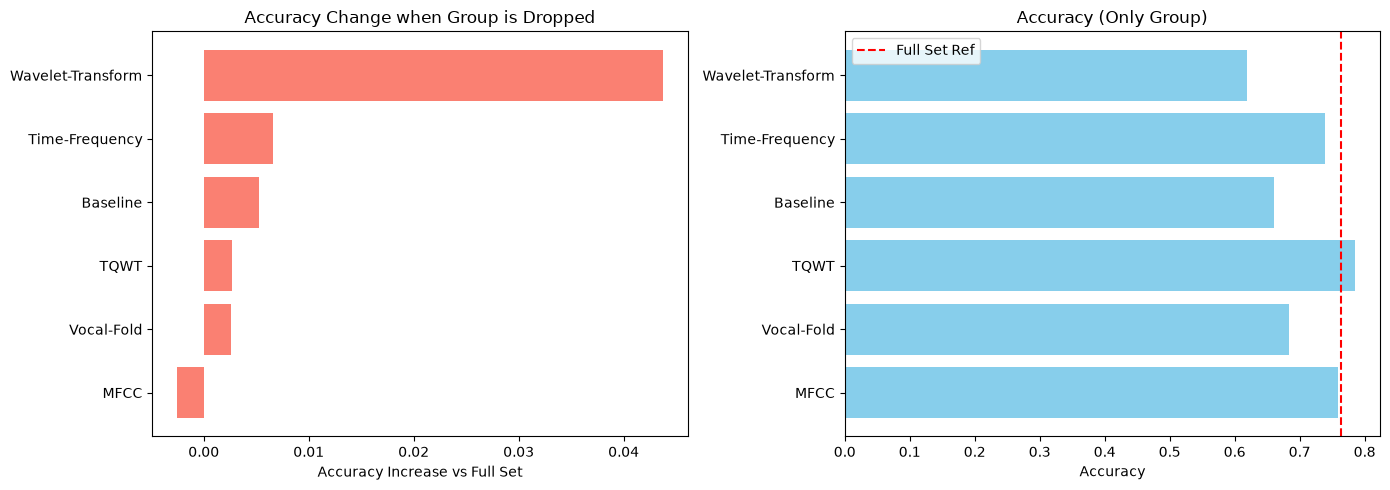

In [2]:
import lightgbm as lgb
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

features = X.columns.tolist()

groups_dict = {
    'Baseline': [f for f in features if any(x in f for x in ['Jitter', 'Shimmer', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE', 'numPulses', 'numPeriodsMean', 'meanPeriod', 'sdPeriod', 'fractionOfUnvoicedFrames', 'numVoiceBreaks', 'degreeOfVoiceBreaks'])],
    'MFCC': [f for f in features if '_MFCC_' in f],
    'TQWT': [f for f in features if f.startswith('tqwt')],
    'Wavelet-Transform': [f for f in features if f.startswith('Ea') or f.startswith('Ed') or f.startswith('det_') or f.startswith('app_')],
}
mapped = set(groups_dict['Baseline'] + groups_dict['MFCC'] + groups_dict['TQWT'] + groups_dict['Wavelet-Transform'])
unmapped = [f for f in features if f not in mapped]

groups_dict['Vocal-Fold'] = [f for f in unmapped if any(x in f for x in ['GQ', 'GNE', 'VFER', 'OQ', 'RPA', 'ROA', 'std_dev_z', 'log_energy'])]
mapped.update(groups_dict['Vocal-Fold'])
unmapped = [f for f in features if f not in mapped]

groups_dict['Time-Frequency'] = [f for f in unmapped if any(x in f.lower() for x in ['f1', 'f2', 'f3', 'b1', 'b2', 'b3', 'intensity'])]
mapped.update(groups_dict['Time-Frequency'])

def evaluate_subset(cols, k_cap):
    X_sub = X[cols]
    gkf = GroupKFold(n_splits=5)
    accs = []
    
    for train_idx, test_idx in gkf.split(X_sub, y, groups):
        X_train, X_test = X_sub.iloc[train_idx], X_sub.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        vt = VarianceThreshold(threshold=0.01)
        X_train = vt.fit_transform(X_train)
        X_test = vt.transform(X_test)
        
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        
        skb = SelectKBest(f_classif, k=min(k_cap, X_train.shape[1]))
        X_train = skb.fit_transform(X_train, y_train)
        X_test = skb.transform(X_test)
        
        smote = SMOTE(random_state=RANDOM_STATE)
        X_train, y_train = smote.fit_resample(X_train, y_train)
        
        model = lgb.LGBMClassifier(verbose=-1, random_state=RANDOM_STATE)
        model.fit(X_train, y_train)
        
        accs.append(accuracy_score(y_test, model.predict(X_test)))
        
    return np.mean(accs)

# Full set reference
ref_acc = evaluate_subset(features, 50)
print(f"Reference Full Set Accuracy: {ref_acc:.4f}")

# Leave-one-group-out (LOGO) and Single-group-only (SGO)
logo_acc = {}
sgo_acc = {}

for g, cols in groups_dict.items():
    if len(cols) == 0: continue
    # LOGO
    logo_cols = [f for f in features if f not in cols]
    logo_acc[g] = evaluate_subset(logo_cols, 50)
    # SGO
    sgo_acc[g] = evaluate_subset(cols, 50)

groups_list = list(logo_acc.keys())

# Plotting Two-Panel Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sort groups by LOGO accuracy 
sorted_groups = sorted(logo_acc.keys(), key=lambda g: logo_acc[g] - ref_acc, reverse=False)

# Panel 1: LOGO Delta (LOGO - Reference)
logo_deltas = [logo_acc[g] - ref_acc for g in sorted_groups]

ax1.barh(sorted_groups, logo_deltas, color='salmon')
ax1.set_title('Accuracy Change when Group is Dropped')
ax1.set_xlabel('Accuracy Increase vs Full Set')

# Panel 2: SGO vs Full Set
sgo_values = [sgo_acc[g] for g in sorted_groups]
ax2.barh(sorted_groups, sgo_values, color='skyblue')
ax2.axvline(ref_acc, color='r', linestyle='--', label='Full Set Ref')
ax2.set_title('Accuracy (Only Group)')
ax2.set_xlabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.savefig("../figures/ablation_study.png", bbox_inches='tight')
plt.savefig("../faculty_review/ablation_study.png", bbox_inches='tight')
plt.show()

# Save tables
pd.DataFrame({
    'Group': groups_list,
    'LOGO_Acc': [logo_acc[g] for g in groups_list],
    'SGO_Acc': [sgo_acc[g] for g in groups_list]
}).to_csv('../results/ablation_results.csv', index=False)
